**Оборудование:** Google Colab (бесплатный тариф с GPU). Убедитесь, что вы выбрали среду выполнения с GPU (`Runtime → Change runtime type → T4 GPU`).

> **Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
>
> Тетрадка выполнена локально (не в Colab) с исходными данными, моделями и параметрами преподавателя: датасет
> `Megnis/ru_sentiment_dataset-50000` (HuggingFace), разбиение 70/15/15; TF-IDF + логистическая регрессия;
> **RuBERT** (`DeepPavlov/rubert-base-cased`) на 20 % обучающих данных — 2 эпохи, батч 16, длина 128, `warmup_steps=500`;
> генерация текста **ruGPT-3 small** (`sberbank-ai/rugpt3small_based_on_gpt2`). Модели и датасет загружаются с
> HuggingFace в кэш `../data/hf_cache`, чекпойнты `Trainer` — в `../data/transformers_work`.
>
> Дополнительно: для оценки вклада предобучения та же архитектура RuBERT дообучена со случайными весами; показано,
> как `temperature` меняет распределение следующего токена у ruGPT-3. Выполнены все три задания в конце: больше эпох,
> добавление других отзывов (RuReviews — отзывы на одежду и аксессуары, GitHub `sismetanin/rureviews`), больший объём обучающих данных.
>
> Технические изменения: устройство выбирается в первой ячейке кода (cuda → mps → cpu; `Trainer` сам использует
> доступный GPU/MPS); `!pip install` закомментирован (пакеты установлены в окружении); прогресс-бары отключены,
> метрики печатаются по эпохам; лучший по валидации чекпойнт перечитывается через `from_pretrained` (см. комментарий
> к функции `load_best`). **Исправления под актуальные версии библиотек:** параметр `logging_dir` убран — в
> transformers 5.x его больше нет в `TrainingArguments` (код заготовки падал бы с ошибкой); тексты берутся как
> `df['text'].to_numpy(dtype=object)` — в pandas 3 `df['text'].values` возвращает не numpy-массив, и
> `train_test_split` на нём падает.

In [1]:
%matplotlib inline
# ── Настройки запуска (добавлено при выполнении работы) ──────────────────────────────────────────
# Устройство: cuda -> mps -> cpu. Режим быстрой проверки NN_SMOKE=1: крошечные подвыборки и 1 эпоха
# (в обычном запуске — параметры из задания). Данные и кэши моделей — в папке ../data.
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # операции, которых нет в MPS, выполняются на CPU
SMOKE = os.environ.get('NN_SMOKE') == '1'
DATA = '../data'
os.makedirs(DATA, exist_ok=True)
os.environ.setdefault('TORCH_HOME', os.path.abspath(os.path.join(DATA, 'torch_cache')))   # веса torchvision
os.environ.setdefault('HF_HOME', os.path.abspath(os.path.join(DATA, 'hf_cache')))         # модели и датасеты HuggingFace
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')   # загрузка с HuggingFace без протокола Xet: на этом Mac он обрывал длинные загрузки

import torch

def get_device():
    """cuda -> mps -> cpu; переменной окружения NN_DEVICE устройство можно задать явно (например, NN_DEVICE=cpu)."""
    if os.environ.get('NN_DEVICE'):
        return torch.device(os.environ['NN_DEVICE'])
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

def S(full, smoke):
    """Параметр запуска: значение из задания (full) или уменьшенное для проверки NN_SMOKE=1 (smoke)."""
    return smoke if SMOKE else full

device = get_device()
print(f'Устройство: {device} | режим: {"быстрая проверка (NN_SMOKE=1)" if SMOKE else "полный запуск"}')

Устройство: mps | режим: полный запуск


# **Практическое занятие: Классификация текстов с помощью трансформеров**

Цель занятия: научиться применять предобученные трансформеры (RuBERT) для классификации русскоязычных текстов, сравнить качество с простыми методами (TF‑IDF + логистическая регрессия), а также познакомиться с генеративными моделями (GPT‑2).

Мы будем использовать датасет **Megnis/ru_sentiment_dataset-50000** – русскоязычные отзывы с метками тональности: 0 – NEUTRAL, 1 – POSITIVE, 2 – NEGATIVE.



In [2]:
# !pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn tqdm   # пакеты установлены в окружении

In [3]:
import gc
import shutil
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from datasets import load_dataset
import torch
import torch.nn.functional as F
# transformers - для работы с ресурсом HuggingFace.
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments, pipeline
from transformers import AutoConfig
from torch.utils.data import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import datasets as hf_datasets
import huggingface_hub
import warnings
warnings.filterwarnings('ignore')
from transformers.utils import logging as hf_logging
hf_datasets.disable_progress_bars(); huggingface_hub.utils.disable_progress_bars()   # без прогресс-баров загрузки
hf_logging.disable_progress_bar()                                                     # и записи/чтения весов
os.environ["TOKENIZERS_PARALLELISM"] = "false"


torch.manual_seed(42)
np.random.seed(42)                                # подвыборка 20 % ниже берётся через np.random.choice
WORK = os.path.join(DATA, 'transformers_work')    # чекпойнты Trainer (удаляются после загрузки лучшей модели)

def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()

device = get_device()
print(f"Using device: {device}")

Using device: mps


**1. Загрузка и анализ данных**

Загрузим датасет `Megnis/ru_sentiment_dataset-50000`. Он содержит только `train` split, поэтому мы сами разделим его на train/validation/test в пропорции 70/15/15 со стратификацией по меткам.

In [4]:
dataset = load_dataset('Megnis/ru_sentiment_dataset-50000', split='train')
df = dataset.to_pandas()
print("Распределение классов:")
print(df['sentiment'].value_counts())
print("\nПримеры текстов:")
print(df.head())

Распределение классов:
sentiment
2    16158
0    16054
1    16000
Name: count, dtype: int64

Примеры текстов:
   Unnamed: 0                                               text  sentiment
0       38060  Неплохой отель, есть бассейн и сауна.Очень пор...          0
1       85314  Плохой ортопед Не ходите никогда к ортопеду Ло...          2
2      153299  Отель расположен в 5 минутах ходьбы от кафедра...          1
3       62771  Стиль обслуживания Салон м. Римская. Совершенн...          2
4      167623  Хороший врач Прикреплена по страховке к данной...          1


In [5]:
X = df['text'].to_numpy(dtype=object)   # в pandas 3 .values у текстовой колонки — не numpy-массив, train_test_split на нём падает
y = df['sentiment'].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

if SMOKE:   # только быстрая проверка: крошечные выборки
    X_train, y_train, X_val, y_val, X_test, y_test = X_train[:640], y_train[:640], X_val[:64], y_val[:64], X_test[:64], y_test[:64]

print(f"Размер обучающей выборки: {len(X_train)}")
print(f"Размер валидационной выборки: {len(X_val)}")
print(f"Размер тестовой выборки: {len(X_test)}")

Размер обучающей выборки: 33748
Размер валидационной выборки: 7232
Размер тестовой выборки: 7232


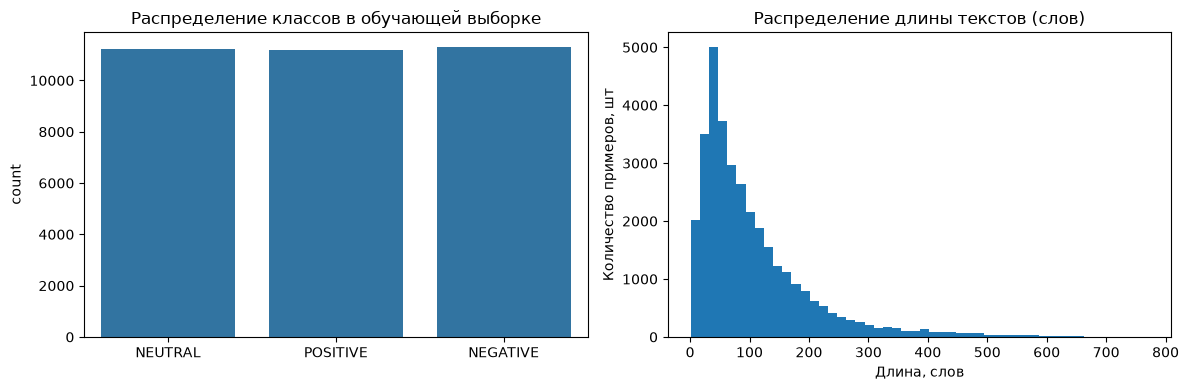

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title('Распределение классов в обучающей выборке')
axes[0].set_xticklabels(['NEUTRAL', 'POSITIVE', 'NEGATIVE'])

lengths = [len(text.split()) for text in X_train]
axes[1].hist(lengths, bins=50)
axes[1].set_title('Распределение длины текстов (слов)')
axes[1].set_xlabel('Длина, слов')
axes[1].set_ylabel('Количество примеров, шт')

plt.tight_layout()
plt.show()

**2. Baseline: TF‑IDF + логистическая регрессия**

Построим простую модель для сравнения. Векторизуем тексты с помощью TF‑IDF (униграммы + биграммы, максимум 10000 признаков) и обучим логистическую регрессию. Это даст нам нижнюю границу качества.

In [7]:
# В качестве токенов используются слова и их парные комбинации ngram_range=(1,2).
# Максимум слов в словаре на все комментарии будет 10000,  остальные будут отброшены (max_features=10000).

vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
t0 = time.perf_counter()
lr.fit(X_train_tfidf, y_train)
print(f'обучение: {time.perf_counter() - t0:.0f} с')

y_test_pred_lr = lr.predict(X_test_tfidf)
print("Baseline (LogReg + TF-IDF):")
print(classification_report(y_test, y_test_pred_lr, target_names=['NEUTRAL', 'POSITIVE', 'NEGATIVE']))
print(f"Accuracy: {accuracy_score(y_test, y_test_pred_lr):.4f}")

обучение: 1 с
Baseline (LogReg + TF-IDF):
              precision    recall  f1-score   support

     NEUTRAL       0.66      0.76      0.71      2408
    POSITIVE       0.75      0.64      0.69      2400
    NEGATIVE       0.79      0.78      0.79      2424

    accuracy                           0.73      7232
   macro avg       0.73      0.73      0.73      7232
weighted avg       0.73      0.73      0.73      7232

Accuracy: 0.7301


In [8]:
X_train_tfidf[0]

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 227 stored elements and shape (1, 10000)>

In [9]:
feature_names = vectorizer.get_feature_names_out()
feature_names

array(['00', '00 до', '000', ..., 'японии', 'ясно', 'қазақстан'],
      shape=(10000,), dtype=object)

In [10]:
len(feature_names)

10000

In [11]:
# Какие слова и биграммы логистическая регрессия считает самыми «окрашенными» для каждого класса
names = ['NEUTRAL', 'POSITIVE', 'NEGATIVE']
for k, name in enumerate(names):
    top = np.argsort(-lr.coef_[k])[:12]
    print(f"{name:9s}: " + ", ".join(feature_names[top]))

NEUTRAL  : неплохой, целом, не очень, но, завтраки, чисто, вариант, завтрак, расположение, принципе, банк, вполне
POSITIVE : благодарность, спасибо, отличный, довольна, благодарю, очень, быстро, поблагодарить, замечательный, прекрасный, лечение, всегда
NEGATIVE : не советую, не рекомендую, ресторана, врач, ужасное, единственный плюс, свадьбу, дозвониться, отношение, руководство, вас, вкусно


**3. Подготовка данных для RuBERT**

Используем русскоязычную модель **DeepPavlov/rubert-base-cased**. Для экономии времени возьмём только 20% обучающих данных (около 7500 примеров), но в полной версии можно использовать всю выборку.

Создадим класс `SentimentDataset` для токенизации и паддинга текстов.

In [12]:
model_name = "DeepPavlov/rubert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

# Для ускорения возьмём подвыборку (20% от train)
sample_size = int(0.2 * len(X_train))
indices = np.random.choice(len(X_train), sample_size, replace=False)
X_train_small = X_train[indices]
y_train_small = y_train[indices]

train_dataset = SentimentDataset(X_train_small, y_train_small, tokenizer)
val_dataset = SentimentDataset(X_val, y_val, tokenizer)
test_dataset = SentimentDataset(X_test, y_test, tokenizer)
print(f'обучение: {len(train_dataset)}, валидация: {len(val_dataset)}, тест: {len(test_dataset)}')

обучение: 6749, валидация: 7232, тест: 7232


**4. Загрузка модели RuBERT и настройка обучения**

Загрузим предобученную модель с классификационной головой на 3 класса. Используем `Trainer` из библиотеки Transformers. Параметры обучения: 2 эпохи, батч 16, оценка на валидации после каждой эпохи.

In [13]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    ignore_mismatched_sizes=True
)

training_args = TrainingArguments(
    output_dir=f'{WORK}/results_main',     # чекпойнты — в ../data, а не рядом с тетрадкой
    num_train_epochs=S(2, 1),
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_steps=500,
    weight_decay=0.01,
    # logging_dir='./logs' — параметр удалён из TrainingArguments в transformers 5.x
    eval_strategy='epoch',          # ← замена evaluation_strategy
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    report_to="none",
    logging_strategy='epoch',         # потери на обучении — в журнал по эпохам
    disable_tqdm=True,                # без прогресс-бара: метрики печатаются по эпохам
    save_total_limit=1,
    save_only_model=True,             # в чекпойнт — только веса (без состояния оптимизатора): меньше места на диске
)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average='weighted')
    return {'accuracy': acc, 'precision': precision, 'recall': recall, 'f1': f1}

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)


def load_best(trainer):
    """Перечитывает лучший по валидации чекпойнт через from_pretrained и освобождает память обучения.

    В выводе тетрадки преподавателя Trainer при load_best_model_at_end сообщал, что не нашёл в чекпойнте веса LayerNorm
    (у RuBERT они названы gamma/beta), — from_pretrained переименовывает такие ключи и загружает все веса.
    После этого чекпойнты на диске больше не нужны и удаляются.
    """
    best = trainer.state.best_model_checkpoint
    trainer.optimizer = trainer.lr_scheduler = None
    trainer.accelerator.free_memory()
    if best:
        print('лучший чекпойнт по валидации:', os.path.basename(best))
        trainer.model = trainer.model_wrapped = AutoModelForSequenceClassification.from_pretrained(best).to(trainer.args.device)
    shutil.rmtree(trainer.args.output_dir, ignore_errors=True)
    free_memory()
    return trainer.model


def make_trainer(model, train_ds, eval_ds, epochs, run):
    """Trainer с теми же настройками, что основной (для заданий в конце тетрадки)."""
    args = TrainingArguments(output_dir=f'{WORK}/results_{run}', num_train_epochs=epochs, per_device_train_batch_size=16,
                             per_device_eval_batch_size=32, warmup_steps=500, weight_decay=0.01, eval_strategy='epoch',
                             save_strategy='epoch', load_best_model_at_end=True, metric_for_best_model='accuracy',
                             report_to='none', logging_strategy='epoch', disable_tqdm=True, save_total_limit=1,
                             save_only_model=True)
    return Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds, compute_metrics=compute_metrics)

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

In [14]:
t0 = time.perf_counter()
trainer.train()
print(f'время дообучения: {time.perf_counter() - t0:.0f} с')
model = load_best(trainer)
pd.DataFrame([r for r in trainer.state.log_history if 'eval_accuracy' in r])[['epoch', 'eval_loss', 'eval_accuracy', 'eval_f1']]

{'loss': '0.7953', 'grad_norm': '10.35', 'learning_rate': '4.21e-05', 'epoch': '1'}


{'eval_loss': '0.6459', 'eval_accuracy': '0.7071', 'eval_precision': '0.7059', 'eval_recall': '0.7071', 'eval_f1': '0.7049', 'eval_runtime': '19.2', 'eval_samples_per_second': '376.7', 'eval_steps_per_second': '11.77', 'epoch': '1'}


{'loss': '0.5339', 'grad_norm': '7.923', 'learning_rate': '1.453e-07', 'epoch': '2'}


{'eval_loss': '0.5423', 'eval_accuracy': '0.7591', 'eval_precision': '0.766', 'eval_recall': '0.7591', 'eval_f1': '0.7581', 'eval_runtime': '19.08', 'eval_samples_per_second': '379.1', 'eval_steps_per_second': '11.85', 'epoch': '2'}


{'train_runtime': '427.4', 'train_samples_per_second': '31.58', 'train_steps_per_second': '1.975', 'train_loss': '0.6646', 'epoch': '2'}


время дообучения: 428 с
лучший чекпойнт по валидации: checkpoint-844


,epoch,eval_loss,eval_accuracy,eval_f1
0,1.0,0.645946,0.707135,0.704928
1,2.0,0.542325,0.759126,0.758051


**5. Оценка модели на тестовой выборке и сравнение с baseline**

In [15]:
test_metrics = trainer.evaluate(test_dataset)
print("RuBERT на тестовой выборке:")
print(test_metrics)

# Получим предсказания для теста
predictions = trainer.predict(test_dataset)
y_pred_bert = np.argmax(predictions.predictions, axis=-1)

print("\nClassification report RuBERT:")
print(classification_report(y_test, y_pred_bert, target_names=['NEUTRAL', 'POSITIVE', 'NEGATIVE']))

print(f"\nAccuracy baseline (TF-IDF): {accuracy_score(y_test, y_test_pred_lr):.4f}")
print(f"Accuracy RuBERT: {test_metrics['eval_accuracy']:.4f}")

{'eval_loss': '0.545', 'eval_model_preparation_time': '0.0013', 'eval_accuracy': '0.7565', 'eval_precision': '0.7637', 'eval_recall': '0.7565', 'eval_f1': '0.7556', 'eval_runtime': '20.81', 'eval_samples_per_second': '347.5', 'eval_steps_per_second': '10.86', 'epoch': '2'}
RuBERT на тестовой выборке:
{'eval_loss': 0.5449552536010742, 'eval_model_preparation_time': 0.0013, 'eval_accuracy': 0.7564988938053098, 'eval_precision': 0.76368170539747, 'eval_recall': 0.7564988938053098, 'eval_f1': 0.7555537122585759, 'eval_runtime': 20.8118, 'eval_samples_per_second': 347.495, 'eval_steps_per_second': 10.859, 'epoch': 2.0}



Classification report RuBERT:
              precision    recall  f1-score   support

     NEUTRAL       0.67      0.80      0.73      2408
    POSITIVE       0.79      0.64      0.70      2400
    NEGATIVE       0.83      0.84      0.83      2424

    accuracy                           0.76      7232
   macro avg       0.76      0.76      0.76      7232
weighted avg       0.76      0.76      0.76      7232


Accuracy baseline (TF-IDF): 0.7301
Accuracy RuBERT: 0.7565


In [16]:
# Что дало предобучение: та же архитектура и те же настройки обучения, но веса RuBERT случайные (без предобучения)
torch.manual_seed(0)
scratch_model = AutoModelForSequenceClassification.from_config(AutoConfig.from_pretrained(model_name, num_labels=3))
trainer_scratch = make_trainer(scratch_model, train_dataset, val_dataset, epochs=S(2, 1), run='scratch')
trainer_scratch.train()
del scratch_model
load_best(trainer_scratch)
acc_scratch = trainer_scratch.evaluate(test_dataset)['eval_accuracy']
del trainer_scratch; free_memory()
results = {f'TF-IDF + LogReg (весь train, {len(X_train)})': accuracy_score(y_test, y_test_pred_lr),
           'та же архитектура без предобучения, 20% train, 2 эпохи': acc_scratch,
           'RuBERT (предобученный), 20% train, 2 эпохи': test_metrics['eval_accuracy']}
for k, v in results.items():
    print(f'{k:<56} точность на тесте {v:.4f}')

{'loss': '1.126', 'grad_norm': '11.37', 'learning_rate': '4.21e-05', 'epoch': '1'}


{'eval_loss': '1.115', 'eval_accuracy': '0.3259', 'eval_precision': '0.416', 'eval_recall': '0.3259', 'eval_f1': '0.2655', 'eval_runtime': '20.74', 'eval_samples_per_second': '348.7', 'eval_steps_per_second': '10.9', 'epoch': '1'}


{'loss': '1.11', 'grad_norm': '5.212', 'learning_rate': '1.453e-07', 'epoch': '2'}


{'eval_loss': '1.075', 'eval_accuracy': '0.3662', 'eval_precision': '0.4755', 'eval_recall': '0.3662', 'eval_f1': '0.3173', 'eval_runtime': '20.73', 'eval_samples_per_second': '348.8', 'eval_steps_per_second': '10.9', 'epoch': '2'}
{'train_runtime': '435.9', 'train_samples_per_second': '30.97', 'train_steps_per_second': '1.936', 'train_loss': '1.118', 'epoch': '2'}


лучший чекпойнт по валидации: checkpoint-844


{'eval_loss': '1.074', 'eval_model_preparation_time': '0.0013', 'eval_accuracy': '0.3587', 'eval_precision': '0.4751', 'eval_recall': '0.3587', 'eval_f1': '0.3097', 'eval_runtime': '20.97', 'eval_samples_per_second': '344.9', 'eval_steps_per_second': '10.78', 'epoch': '2'}
TF-IDF + LogReg (весь train, 33748)                      точность на тесте 0.7301
та же архитектура без предобучения, 20% train, 2 эпохи   точность на тесте 0.3587
RuBERT (предобученный), 20% train, 2 эпохи               точность на тесте 0.7565


**6. Визуализация матрицы ошибок**

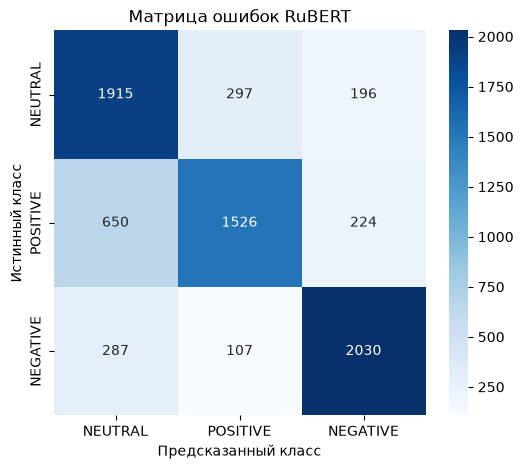

In [17]:
cm = confusion_matrix(y_test, y_pred_bert)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['NEUTRAL', 'POSITIVE', 'NEGATIVE'], yticklabels=['NEUTRAL', 'POSITIVE', 'NEGATIVE'])
plt.title('Матрица ошибок RuBERT')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()

**7. Инференс на новых примерах**

Теперь можно использовать обученную модель для классификации произвольных текстов. Создадим функцию, которая принимает текст и возвращает предсказанную тональность.

In [18]:
def predict_sentiment(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=128).to(device)
    model.to(device)
    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
        pred = torch.argmax(outputs.logits, dim=1).item()
    return pred

sample_texts = [
    "Отличный фильм, очень понравился!",
    "Ужасное обслуживание, больше не приду.",
    "Нормально, ничего особенного.",
    """
    О фильме: Картина была представлена в рамках внеконкурсной программы Дикие ночи 47 Московского международного кинофестиваля. На русский язык фильм озвучили Евгений Рыбов и Мария Трындяйкина — «золотые голоса» MTV, «Южного парка», «Клиники» и «Семейки Осборнов».

    Сюжет: Над маленьким американским городком Марлоу нависла угроза — их пытаются поработить вампиры-зомби… из космоса.

    Мнение: Есть жанры фильмов, которые нравятся не всем, например, пародийные комедии — «Очень страшное кино», «Голый пистолет», «Горячие головы» и прочие. Обычно в них упрощенный сюжет, утрированные и глупые персонажи, юмор ниже пояса и пародия на десятки культовых или актуальных фильмов. Также неоднозначны фильмы про мультивселенные и альтернативные реальности под девизом «А что, если…»…

    А что, если смешать вампиров и зомби, и пусть они прилетят из космоса. И всё это будет в «лучших» традициях фильмов ужасов категории «В» 50-х годов, с отсылками и клише классических ужастиков. Я не знаю, как это могло прийти кому-то в голову — сделать нарочито «плохой» фильм с подобным подтекстом, но у режиссера Майкла Стасько, в большинстве своем, задумка сработала.

    И получилась не столько пародия и высмеивание «страшилок без бюджета», сколько дань уважения и почтения забытым и утонувшим в современных спецэффектах малобюджетным хоррорам. Все эти декорации из фольги, неряшливый грим, игрушечные летучие мыши, летающие тарелки на ниточках, бутафорские конечности и литры «кетчупа» — всё это навевает ностальгические чувства с одной стороны и показывает какой огромный шаг сделал кинематограф с другой стороны.

    Для просмотра нужен определенный настрой. Ужастики 50-х годов для многих зрителей ничего уже не говорят, это было очень давно, большинство из них еще не родились, поэтому в полной мере насладиться ностальгией не получится. К тому же намешанный сюжет, местами буксующий, с неравномерными шутками, периодически скатывается к полной несуразице. Но, если отбросить всю аналитику и настроиться на хороший вечер за просмотром пародийного кино, то от данного фильма удастся получить удовольствие.   "
"""
]

for text in sample_texts:
    pred = predict_sentiment(text)
    sentiment = ['NEUTRAL', 'POSITIVE', 'NEGATIVE'][pred]
    print(f"Текст: {text}")
    print(f"Предсказание: {sentiment}\n")

Текст: Отличный фильм, очень понравился!
Предсказание: POSITIVE

Текст: Ужасное обслуживание, больше не приду.
Предсказание: NEGATIVE

Текст: Нормально, ничего особенного.
Предсказание: NEUTRAL

Текст: 
    О фильме: Картина была представлена в рамках внеконкурсной программы Дикие ночи 47 Московского международного кинофестиваля. На русский язык фильм озвучили Евгений Рыбов и Мария Трындяйкина — «золотые голоса» MTV, «Южного парка», «Клиники» и «Семейки Осборнов».

    Сюжет: Над маленьким американским городком Марлоу нависла угроза — их пытаются поработить вампиры-зомби… из космоса.

    Мнение: Есть жанры фильмов, которые нравятся не всем, например, пародийные комедии — «Очень страшное кино», «Голый пистолет», «Горячие головы» и прочие. Обычно в них упрощенный сюжет, утрированные и глупые персонажи, юмор ниже пояса и пародия на десятки культовых или актуальных фильмов. Также неоднозначны фильмы про мультивселенные и альтернативные реальности под девизом «А что, если…»…

    А что, ес

**8. (Опционально) Демонстрация генерации текста с помощью GPT‑2**

Для иллюстрации работы декодерной модели используем предобученную GPT‑2 (маленькую версию) и сгенерируем продолжение текста. Это поможет понять разницу между BERT (понимание) и GPT (генерация).

In [19]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer

gpt_model_name = "sberbank-ai/rugpt3small_based_on_gpt2"  # небольшая русскоязычная GPT
torch.manual_seed(42)                       # воспроизводимость сэмплирования
gpt_tokenizer = GPT2Tokenizer.from_pretrained(gpt_model_name)
gpt_model = GPT2LMHeadModel.from_pretrained(gpt_model_name)

gpt_tokenizer.pad_token = gpt_tokenizer.eos_token

prompt = "Сегодня я решил попробовать новый ресторан"
inputs = gpt_tokenizer(prompt, return_tensors='pt')

output = gpt_model.generate(
    **inputs,
    max_new_tokens=50,
    do_sample=True,
    temperature=0.8,
    top_p=0.9,
    pad_token_id=gpt_tokenizer.eos_token_id
)

generated_text = gpt_tokenizer.decode(output[0], skip_special_tokens=True)
print("Промпт:", prompt)
print("Сгенерированный текст:", generated_text)

[transformers] GPT2LMHeadModel LOAD REPORT from: sberbank-ai/rugpt3small_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Промпт: Сегодня я решил попробовать новый ресторан
Сгенерированный текст: Сегодня я решил попробовать новый ресторан, который меня устраивает по многим параметрам. 












































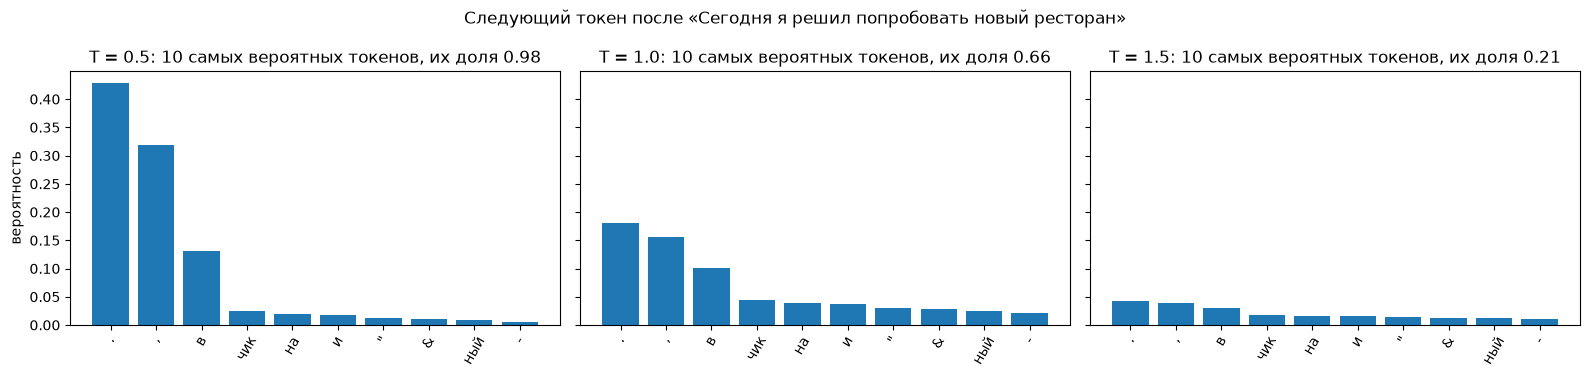

temperature=0.3, top_k=—, top_p=1.0: Сегодня я решил попробовать новый ресторан, который называется "Санта-Барбара".  Это ресторан, где подают блюда из морепродуктов, а также блюда из морепродуктов.


temperature=0.8, top_k=—, top_p=0.9: Сегодня я решил попробовать новый ресторан - "Новогодняя открытка" - на берегу Белого моря, в пяти минутах ходьбы от Белого дома.  Вкусная еда, красивая живая


temperature=1.0, top_k=—, top_p=1.0: Сегодня я решил попробовать новый ресторан - "Новокренский", открывающий все двери Четвертого канала в 20:00.Открытие кафе начинается уже почти в 2:20 ночи


temperature=1.5, top_k=—, top_p=1.0: Сегодня я решил попробовать новый ресторан - московский Горбрендеев Валентин Вячеславович предлагает фасованные мусаки пылесос ( Ольхот Кинг Запад Бегини Граф Жигьэль Мез Комплекс


temperature=1.0, top_k=5, top_p=1.0: Сегодня я решил попробовать новый ресторан, где я буду готовить и в котором буду делать заказ, и я не знаю, что мне будет полезно.  Я думаю, что это будет интересно


temperature=1.0, top_k=—, top_p=0.5: Сегодня я решил попробовать новый ресторан, расположенный в районе Нарочь-Марья.  Я приехал в гостиницу "Белый Бим", но уже поздно вечером.  К тому


In [20]:
# Как temperature меняет распределение следующего токена и что получается при генерации
gpt_model.eval()
with torch.no_grad():
    logits = gpt_model(**gpt_tokenizer(prompt, return_tensors='pt')).logits[0, -1]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, T_ in zip(axes, [0.5, 1.0, 1.5]):
    p = F.softmax(logits / T_, dim=-1)
    top = torch.topk(p, 10)
    ax.bar([gpt_tokenizer.decode([int(i)]).strip() or '␣' for i in top.indices], top.values.numpy(), color='C0')
    ax.set_title(f'T = {T_}: 10 самых вероятных токенов, их доля {top.values.sum():.2f}')
    ax.tick_params(axis='x', rotation=60)
axes[0].set_ylabel('вероятность')
plt.suptitle(f'Следующий токен после «{prompt}»'); plt.tight_layout(); plt.show()

for T_, k, p_ in [(0.3, 0, 1.0), (0.8, 0, 0.9), (1.0, 0, 1.0), (1.5, 0, 1.0), (1.0, 5, 1.0), (1.0, 0, 0.5)]:
    torch.manual_seed(0)
    out = gpt_model.generate(**gpt_tokenizer(prompt, return_tensors='pt'), max_new_tokens=30, do_sample=True,
                             temperature=T_, top_k=k, top_p=p_, pad_token_id=gpt_tokenizer.eos_token_id)
    print(f"temperature={T_}, top_k={k or '—'}, top_p={p_}: {gpt_tokenizer.decode(out[0], skip_special_tokens=True)}")

**Генерация ruGPT-3 small** (промпт «Сегодня я решил попробовать новый ресторан»).

- **Ячейка заготовки** (`temperature = 0.8`, `top_p = 0.9`, до 50 новых токенов) дала одно связное предложение («…который меня устраивает по многим параметрам.»), а остаток бюджета ушёл на пустые строки. Модель выбрала перевод строки и дальше продолжала только его. Это типичная ошибка маленькой модели: она «застревает» в повторении одного токена.
- **Распределение следующего токена.** Самые вероятные продолжения — точка, запятая, «в», «чик» (из «ресторанчик»), «на», «и». Температура меняет только форму распределения, но не порядок токенов. При T = 0,5 на десять самых вероятных токенов приходится 98 % вероятности, и почти всегда будет выбрана точка или запятая. При T = 1,0 — 66 %, при T = 1,5 — 21 %: распределение почти плоское, и в выборку попадают редкие токены.
- **Генерации при разных настройках** (одно и то же зерно):
  - T = 0,3 — связно, но с повтором: «подают блюда из морепродуктов, а также блюда из морепродуктов»;
  - T = 0,8 и top_p = 0,9 — грамматически правильный текст с выдуманными фактами («на берегу Белого моря, в пяти минутах ходьбы от Белого дома»);
  - T = 1,0 — связность заметно падает;
  - T = 1,5 — набор слов и обрывков имён без смысла;
  - top_k = 5 и top_p = 0,5 при T = 1,0 урезают «хвост» распределения, и текст снова связный, хотя и пустой по содержанию.

**Вывод.** Декодерная модель хорошо продолжает текст грамматически, но не знает фактов и легко повторяется. Качество генерации управляется стратегией выборки: низкая температура и узкий top_k/top_p дают связный, но однообразный текст, высокая температура — разнообразный, но бессвязный. Разумный компромисс здесь — T ≈ 0,7–1,0 вместе с top_p ≈ 0,5–0,9.

**9. Выводы**

**Данные.** 48 212 отзывов, классы сбалансированы (по ~16 000). Судя по примерам и словам-маркерам, это отзывы об организациях и услугах: отели, врачи, салоны, рестораны, банки. Разбиение 70/15/15: 33 748 / 7 232 / 7 232. Тексты длинные: большинство — 20–150 слов, хвост до 700 слов.

| модель | обучающих текстов | точность на тесте |
|---|---|---|
| TF-IDF + логистическая регрессия | 33 748 (весь train) | 0,730 |
| **RuBERT, 2 эпохи (как в заготовке)** | 6 749 (20 %) | **0,757** |
| та же архитектура без предобучения, 2 эпохи | 6 749 (20 %) | 0,359 |

- **TF-IDF против RuBERT.** RuBERT на пятой части данных точнее TF-IDF, обученного на всех данных, на 2,6 п. п. (macro-F1 0,76 против 0,73). Выигрыш есть, но не такой большой, как сказано в выводах заготовки («трансформеры значительно превосходят»). При обучении на всех данных разрыв вырастает до 6 п. п. (0,791, задание 3).
- **TF-IDF силён на этих данных**, потому что тональность во многом выражается отдельными словами и сочетаниями. Самые «весомые» признаки логистической регрессии:
  - положительный класс: «благодарность», «спасибо», «отличный», «довольна»;
  - отрицательный: «не советую», «не рекомендую», «ужасное», «единственный плюс»;
  - нейтральный: «неплохой», «в целом», «не очень», «но».

  RuBERT дополнительно учитывает порядок слов и контекст, отсюда прирост.
- **Что дало предобучение.** Та же архитектура со случайными весами за те же 2 эпохи на 6,7 тыс. текстов почти ничего не выучила: 0,359 при 0,333 для случайного угадывания. Train loss остаётся около 1,1, то есть на уровне ln 3. Сеть почти со 180 млн параметров с нуля на таком объёме не обучить. Вся полезная работа RuBERT — это знание языка, полученное при предобучении. Дообучение лишь настраивает поверх него классификатор.
- **Где ошибается модель** (матрица ошибок на тесте):
  - лучше всего распознаются отрицательные отзывы (recall 0,84, F1 0,83);
  - хуже всего — положительные: 650 из 2 400 (27 %) отнесены к нейтральным, recall 0,64;
  - нейтральные модель предсказывает слишком часто: recall 0,80 при precision 0,67.

  Граница «положительный — нейтральный» нечёткая и в самих данных: в нейтральных отзывах часто есть и похвала, и оговорки («неплохой», «в целом»). У TF-IDF ошибки такие же: recall положительного класса тоже 0,64.
- **Инференс.**
  - Три коротких примера классифицированы верно: «Отличный фильм…» — POSITIVE, «Ужасное обслуживание…» — NEGATIVE, «Нормально, ничего особенного» — NEUTRAL.
  - Длинная рецензия на фильм получила NEUTRAL. В ней действительно много оговорок, но итоговое мнение («удастся получить удовольствие») стоит в самом конце, а модель видит только первые 128 токенов — описание и сюжет.
  - Для длинных текстов ограничение длины входа существенно.

В этом практическом занятии мы:
*   Загрузили и проанализировали датасет русскоязычных отзывов.
*   Построили базовую модель на TF‑IDF и логистической регрессии.
*   Тонко настроили модель RuBERT для классификации тональности.
*   Сравнили качество: трансформеры значительно превосходят простые методы.
*   Попробовали генерировать текст с помощью GPT‑2.

**Важные замечания:**
*   Для ускорения обучения мы использовали только 20% обучающих данных. При использовании всей выборки качество может быть выше.
*   Для русскоязычных задач важно выбирать модели, обученные на русском языке (RuBERT, ruGPT и др.).
*   Трансформеры требуют больше вычислительных ресурсов, но обеспечивают гораздо лучшее качество.

Теперь вы можете применить эти техники к своим данным в рамках финального проекта!

**Задания:**
1. Попробовать большее количество эпох.
2. Попробовать добавить другие отзывы о фильмах или не только о фильмах.
3. Попробовать использовать более объёмный набор данных или свой по интересу или из ВКРМ.

### Задание 1. Больше эпох

Тот же предобученный RuBERT, те же 20 % обучающих данных и настройки, но 6 эпох вместо 2 (в конце обучения загружается лучшая по валидации эпоха).

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

{'loss': '0.8017', 'grad_norm': '6.855', 'learning_rate': '4.21e-05', 'epoch': '1'}


{'eval_loss': '0.6886', 'eval_accuracy': '0.6966', 'eval_precision': '0.6949', 'eval_recall': '0.6966', 'eval_f1': '0.6946', 'eval_runtime': '19.08', 'eval_samples_per_second': '379', 'eval_steps_per_second': '11.84', 'epoch': '1'}


{'loss': '0.5811', 'grad_norm': '5.788', 'learning_rate': '4.156e-05', 'epoch': '2'}


{'eval_loss': '0.6596', 'eval_accuracy': '0.7161', 'eval_precision': '0.7142', 'eval_recall': '0.7161', 'eval_f1': '0.7108', 'eval_runtime': '19.07', 'eval_samples_per_second': '379.2', 'eval_steps_per_second': '11.85', 'epoch': '2'}


...

{'eval_loss': '1.524', 'eval_accuracy': '0.7377', 'eval_precision': '0.7371', 'eval_recall': '0.7377', 'eval_f1': '0.7374', 'eval_runtime': '19.04', 'eval_samples_per_second': '379.9', 'eval_steps_per_second': '11.87', 'epoch': '5'}


{'loss': '0.02714', 'grad_norm': '0.01062', 'learning_rate': '2.461e-08', 'epoch': '6'}


{'eval_loss': '1.595', 'eval_accuracy': '0.7417', 'eval_precision': '0.7418', 'eval_recall': '0.7417', 'eval_f1': '0.7415', 'eval_runtime': '19.05', 'eval_samples_per_second': '379.6', 'eval_steps_per_second': '11.86', 'epoch': '6'}
{'train_runtime': '1277', 'train_samples_per_second': '31.7', 'train_steps_per_second': '1.982', 'train_loss': '0.338', 'epoch': '6'}


лучший чекпойнт по валидации: checkpoint-2532


{'eval_loss': '1.584', 'eval_model_preparation_time': '0.0013', 'eval_accuracy': '0.7428', 'eval_precision': '0.7432', 'eval_recall': '0.7428', 'eval_f1': '0.7428', 'eval_runtime': '20.61', 'eval_samples_per_second': '351', 'eval_steps_per_second': '10.97', 'epoch': '6'}
 epoch  eval_loss  eval_accuracy  eval_f1
   1.0   0.688578       0.696626 0.694592
   2.0   0.659563       0.716123 0.710751
   3.0   0.782204       0.689989 0.677696
   4.0   1.058604       0.724419 0.721391
   5.0   1.524042       0.737694 0.737382
   6.0   1.595248       0.741704 0.741523
точность на тесте (лучшая эпоха по валидации): 0.7428  (1278 с)


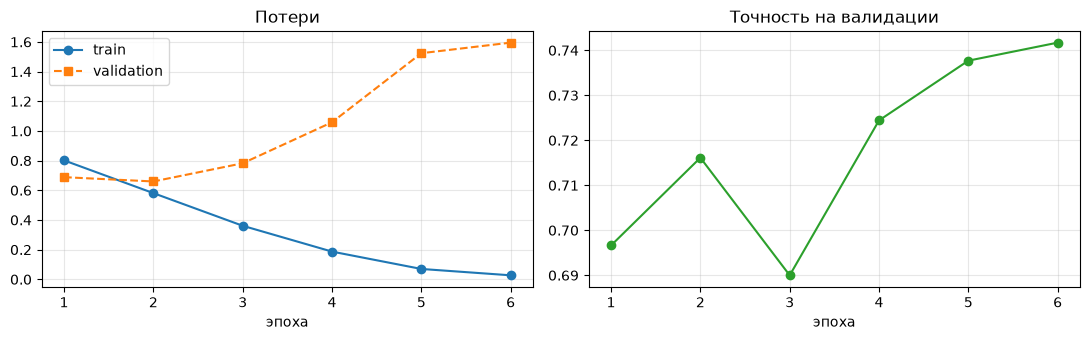

In [21]:
torch.manual_seed(0)
model_e6 = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3, ignore_mismatched_sizes=True)
trainer_e6 = make_trainer(model_e6, train_dataset, val_dataset, epochs=S(6, 2), run='e6')
t0 = time.perf_counter(); trainer_e6.train(); t_e6 = time.perf_counter() - t0
del model_e6
load_best(trainer_e6)
hist_e6 = pd.DataFrame([r for r in trainer_e6.state.log_history if 'eval_accuracy' in r])
train_loss_e6 = [r['loss'] for r in trainer_e6.state.log_history if 'loss' in r and 'eval_loss' not in r]
results['RuBERT, 20% train, 6 эпох'] = trainer_e6.evaluate(test_dataset)['eval_accuracy']
del trainer_e6; free_memory()
print(hist_e6[['epoch', 'eval_loss', 'eval_accuracy', 'eval_f1']].to_string(index=False))
print(f"точность на тесте (лучшая эпоха по валидации): {results['RuBERT, 20% train, 6 эпох']:.4f}  ({t_e6:.0f} с)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(range(1, len(train_loss_e6) + 1), train_loss_e6, 'o-', label='train'); ax[0].plot(hist_e6['epoch'], hist_e6['eval_loss'], 's--', label='validation')
ax[0].set_title('Потери'); ax[0].legend(); ax[0].set_xlabel('эпоха')
ax[1].plot(hist_e6['epoch'], hist_e6['eval_accuracy'], 'o-', color='C2'); ax[1].set_title('Точность на валидации'); ax[1].set_xlabel('эпоха')
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Задание 2. Добавить другие отзывы, не только из основного набора

Добавим к обучению отзывы из **RuReviews** (Smetanin & Komarov, 2019; GitHub `sismetanin/rureviews`) — отзывы покупателей на женскую одежду и аксессуары с метками positive / neautral / negative (так написано в исходном файле). Это другой домен: отзывы о товарах, а не комментарии из основного набора.

Чтобы добавленные тексты не заслонили основной набор, берём из RuReviews стратифицированную выборку такого размера, чтобы её 85 % совпадали по объёму с текущей обучающей частью (20 % основного набора); оставшиеся 15 % выборки — тест на отзывах о товарах. Сравниваются модели, обученные только на основном наборе и на основном наборе + RuReviews (2 эпохи, остальные настройки те же).

In [22]:
import urllib.request
RUREV_URL = 'https://raw.githubusercontent.com/sismetanin/rureviews/master/women-clothing-accessories.3-class.balanced.csv'
rv_path = os.path.join(DATA, 'rureviews_women-clothing-accessories.3-class.balanced.csv')
if not os.path.exists(rv_path):
    urllib.request.urlretrieve(RUREV_URL, rv_path)
rv = pd.read_csv(rv_path, sep='\t')
rv['sentiment'] = rv['sentiment'].map({'neautral': 0, 'positive': 1, 'negative': 2})   # кодировка как в основном наборе
rv = rv.dropna(subset=['review', 'sentiment']).rename(columns={'review': 'text'})
n_take = int(round(len(X_train_small) / 0.85)) if not SMOKE else 300
rv = pd.concat([g.sample(n_take // 3, random_state=0) for _, g in rv.groupby('sentiment')])   # поровну из каждого класса
print('RuReviews по классам (0/1/2):', rv['sentiment'].value_counts().sort_index().tolist(), '| пример:', rv['text'].iloc[3][:100])
rv_train, rv_test = train_test_split(rv, test_size=0.15, random_state=42, stratify=rv['sentiment'])
rv_test_ds = SentimentDataset(rv_test['text'].to_numpy(dtype=object), rv_test['sentiment'].to_numpy().astype(int), tokenizer)

mix_ds = SentimentDataset(np.concatenate([X_train_small, rv_train['text'].to_numpy(dtype=object)]),
                          np.concatenate([y_train_small, rv_train['sentiment'].to_numpy().astype(int)]), tokenizer)
print(f'обучение: {len(X_train_small)} текстов основного набора + {len(rv_train)} отзывов RuReviews; тест на RuReviews: {len(rv_test)}')
torch.manual_seed(0)
model_mix = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3, ignore_mismatched_sizes=True)
trainer_mix = make_trainer(model_mix, mix_ds, val_dataset, epochs=S(2, 1), run='mix')
trainer_mix.train()
del model_mix
load_best(trainer_mix)

rows = []
for name, tr in [('только основной (20%)', trainer), ('основной (20%) + RuReviews', trainer_mix)]:
    rows.append((name, tr.evaluate(test_dataset)['eval_accuracy'], tr.evaluate(rv_test_ds)['eval_accuracy']))
results['RuBERT, 20% train + RuReviews, 2 эпохи'] = rows[1][1]
del trainer_mix; free_memory()
# Для сравнения — базовая модель TF-IDF на RuReviews
rv_lr = accuracy_score(rv_test['sentiment'].astype(int), lr.predict(vectorizer.transform(rv_test['text'])))
print(f"\n{'обучение':<28}{'тест: основной':>16}{'тест: RuReviews':>17}")
for name, a_main, a_rv in rows:
    print(f"{name:<28}{a_main:>16.4f}{a_rv:>17.4f}")
print(f"{'TF-IDF (только основной)':<28}{accuracy_score(y_test, y_test_pred_lr):>16.4f}{rv_lr:>17.4f}")
print(f"доля самого частого класса в тесте RuReviews: {rv_test['sentiment'].value_counts(normalize=True).max():.4f}")

RuReviews по классам (0/1/2): [2646, 2646, 2646] | пример: короткие рукава
обучение: 6749 текстов основного набора + 6747 отзывов RuReviews; тест на RuReviews: 1191


[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

{'loss': '0.7717', 'grad_norm': '13.79', 'learning_rate': '3.556e-05', 'epoch': '1'}


{'eval_loss': '0.6467', 'eval_accuracy': '0.7017', 'eval_precision': '0.6991', 'eval_recall': '0.7017', 'eval_f1': '0.6999', 'eval_runtime': '19.01', 'eval_samples_per_second': '380.5', 'eval_steps_per_second': '11.89', 'epoch': '1'}


{'loss': '0.4935', 'grad_norm': '9.494', 'learning_rate': '4.209e-08', 'epoch': '2'}


...

лучший чекпойнт по валидации: checkpoint-1688


{'eval_loss': '0.545', 'eval_model_preparation_time': '0.0013', 'eval_accuracy': '0.7565', 'eval_precision': '0.7637', 'eval_recall': '0.7565', 'eval_f1': '0.7556', 'eval_runtime': '20.74', 'eval_samples_per_second': '348.7', 'eval_steps_per_second': '10.9', 'epoch': '2'}


{'eval_loss': '1.322', 'eval_model_preparation_time': '0.0013', 'eval_accuracy': '0.4929', 'eval_precision': '0.6506', 'eval_recall': '0.4929', 'eval_f1': '0.4673', 'eval_runtime': '3.359', 'eval_samples_per_second': '354.6', 'eval_steps_per_second': '11.31', 'epoch': '2'}


{'eval_loss': '0.5709', 'eval_model_preparation_time': '0.0013', 'eval_accuracy': '0.7575', 'eval_precision': '0.7659', 'eval_recall': '0.7575', 'eval_f1': '0.7567', 'eval_runtime': '20.8', 'eval_samples_per_second': '347.6', 'eval_steps_per_second': '10.86', 'epoch': '2'}


{'eval_loss': '0.6356', 'eval_model_preparation_time': '0.0013', 'eval_accuracy': '0.7271', 'eval_precision': '0.7383', 'eval_recall': '0.7271', 'eval_f1': '0.7311', 'eval_runtime': '3.318', 'eval_samples_per_second': '358.9', 'eval_steps_per_second': '11.45', 'epoch': '2'}

обучение                      тест: основной  тест: RuReviews
только основной (20%)                 0.7565           0.4929
основной (20%) + RuReviews            0.7575           0.7271
TF-IDF (только основной)              0.7301           0.5701
доля самого частого класса в тесте RuReviews: 0.3333


### Задание 3. Более объёмный набор данных

Вся обучающая часть (70 % датасета) вместо 20 %, 2 эпохи, остальные настройки те же.

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

{'loss': '0.6347', 'grad_norm': '7.36', 'learning_rate': '2.837e-05', 'epoch': '1'}


{'eval_loss': '0.5309', 'eval_accuracy': '0.7622', 'eval_precision': '0.7792', 'eval_recall': '0.7622', 'eval_f1': '0.762', 'eval_runtime': '19.05', 'eval_samples_per_second': '379.6', 'eval_steps_per_second': '11.86', 'epoch': '1'}


{'loss': '0.4054', 'grad_norm': '30.03', 'learning_rate': '1.344e-08', 'epoch': '2'}


{'eval_loss': '0.5297', 'eval_accuracy': '0.7811', 'eval_precision': '0.7818', 'eval_recall': '0.7811', 'eval_f1': '0.7808', 'eval_runtime': '19.01', 'eval_samples_per_second': '380.4', 'eval_steps_per_second': '11.89', 'epoch': '2'}
{'train_runtime': '4302', 'train_samples_per_second': '15.69', 'train_steps_per_second': '0.981', 'train_loss': '0.52', 'epoch': '2'}


лучший чекпойнт по валидации: checkpoint-4220


{'eval_loss': '0.5183', 'eval_model_preparation_time': '0.0012', 'eval_accuracy': '0.7907', 'eval_precision': '0.7912', 'eval_recall': '0.7907', 'eval_f1': '0.7902', 'eval_runtime': '84.44', 'eval_samples_per_second': '85.65', 'eval_steps_per_second': '2.677', 'epoch': '2'}
 epoch  eval_loss  eval_accuracy  eval_f1
   1.0   0.530874       0.762168 0.762006
   2.0   0.529724       0.781112 0.780820
точность на тесте: 0.7907  (2018 с)


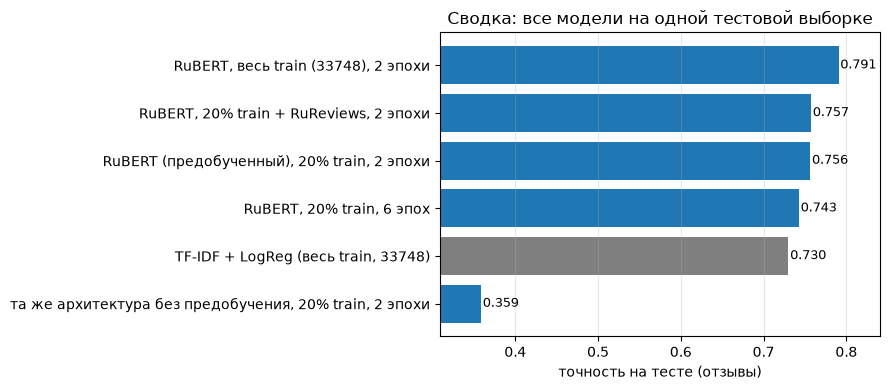

In [23]:
full_train_ds = SentimentDataset(X_train, y_train, tokenizer)
torch.manual_seed(0)
model_full = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3, ignore_mismatched_sizes=True)
trainer_full = make_trainer(model_full, full_train_ds, val_dataset, epochs=S(2, 1), run='full')
t0 = time.perf_counter(); trainer_full.train(); t_full = time.perf_counter() - t0
del model_full
load_best(trainer_full)
hist_full = pd.DataFrame([r for r in trainer_full.state.log_history if 'eval_accuracy' in r])   # валидация по эпохам
results[f'RuBERT, весь train ({len(X_train)}), 2 эпохи'] = trainer_full.evaluate(test_dataset)['eval_accuracy']
del trainer_full; free_memory()
print(hist_full[['epoch', 'eval_loss', 'eval_accuracy', 'eval_f1']].to_string(index=False))
print(f"точность на тесте: {results[f'RuBERT, весь train ({len(X_train)}), 2 эпохи']:.4f}  ({t_full:.0f} с)")

res_df = pd.Series(results).sort_values()
plt.figure(figsize=(9, 4))
bars = plt.barh(res_df.index, res_df.values, color=['C7' if 'TF-IDF' in k else 'C0' for k in res_df.index])
for b_, v in zip(bars, res_df.values):
    plt.text(v + 0.002, b_.get_y() + b_.get_height() / 2, f'{v:.3f}', va='center', fontsize=9)
plt.xlim(max(0, res_df.min() - 0.05), min(1, res_df.max() + 0.05)); plt.xlabel('точность на тесте (отзывы)')
plt.title('Сводка: все модели на одной тестовой выборке'); plt.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

**Задание 1. Больше эпох** (20 % данных, 6 эпох вместо 2):

| эпоха | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| val accuracy | 0,697 | 0,716 | 0,690 | 0,724 | 0,738 | **0,742** |
| val loss | 0,689 | **0,660** | 0,782 | 1,059 | 1,524 | 1,595 |

- **Тест (лучшая эпоха по точности на валидации — 6-я): 0,743**, то есть хуже, чем после 2 эпох (0,757).
- Модель переобучается: train loss падает до 0,03, а val loss после 2-й эпохи растёт в 2,4 раза. Точность при этом ещё немного растёт: модель становится излишне уверенной в своих ошибках, а доля верных ответов меняется мало.
- Есть и вторая причина. Скорость обучения линейно уменьшается до нуля к концу обучения. При 2 эпохах вторая эпоха проходит при малой скорости обучения, а при 6 эпохах на 2–3-й эпохах она ещё высокая, и веса сильнее «уходят» от предобученных.
- **Вывод:** на 6,7 тыс. текстов 2 эпохи достаточно, больше эпох — переобучение. Если учить дольше, выбирать модель нужно по val loss или с ранней остановкой.

**Задание 2. Другие отзывы.** К 6 749 текстам основного набора добавлены 6 747 отзывов RuReviews (одежда и аксессуары, по 1/3 каждого класса). Тест — 1 191 отзыв RuReviews.

| обучение | тест: основной | тест: RuReviews |
|---|---|---|
| только основной (20 %) | 0,757 | 0,493 |
| основной + RuReviews | **0,758** | **0,727** |
| TF-IDF (только основной) | 0,730 | 0,570 |

- Модель, обученная только на отзывах об услугах, на отзывах о товарах работает плохо: 0,493 при уровне случайного угадывания 0,333. Это даже хуже TF-IDF (0,570). Домены сильно различаются: отзывы о товарах короткие («короткие рукава»), и тональность выражается другими словами (размер, ткань, доставка).
- После добавления RuReviews точность на товарах выросла до 0,727 (+23 п. п.), а на основном наборе не упала (0,758 против 0,757).
- **Вывод:** данные из нового домена нужно добавлять в обучение — одна модель может хорошо работать на обоих доменах.

**Задание 3. Больший объём данных** (весь train — 33 748 текстов, 2 эпохи):
- точность на валидации 0,762 → 0,781 по эпохам, **на тесте 0,791** — лучший результат практики;
- это +3,4 п. п. к модели на 20 % данных и +6,1 п. п. к TF-IDF на тех же данных;
- обучение заняло около 34 мин счёта, в 5 раз дольше, чем на 20 % (по часам дольше — 72 мин, `train_runtime`: в это время Mac, по-видимому, уходил в сон).

**Итог по заданиям:** больше данных — самый надёжный способ улучшить модель (0,757 → 0,791). Больше эпох на малом объёме вредит (0,743). Данные другого домена резко улучшают качество на этом домене, не ухудшая основной.

**Заключение:**
1. Новые навыки/умения/знания.
2. Пожелания по содержимому лекционного и практического блокнотов, по способу предоставления материала.


**Что нового.**
- Освоил полный цикл дообучения трансформера через `Trainer`: токенизация с ограничением длины, `TrainingArguments`, оценка по эпохам, выбор лучшего чекпойнта. Заодно разобрался с изменениями API в transformers 5.x: `eval_strategy` вместо `evaluation_strategy`, нет `logging_dir`.
- Понял на опыте, сколько даёт предобучение. Та же архитектура без предобученных весов на 6,7 тыс. текстов не учится совсем (0,36), а с ними даёт 0,76.
- Увидел, как температура, top_k и top_p меняют распределение следующего токена и качество генерации.
- Проверил перенос между доменами: модель, обученная на отзывах об услугах, плохо работает на отзывах о товарах, пока их не добавить в обучение.

**Пожелания по материалам.**
- Обновить код под текущие версии transformers и pandas: параметр `logging_dir` уже не поддерживается, а `df['text'].values` в pandas 3 не работает с `train_test_split`.
- Вывод «трансформеры значительно превосходят простые методы» на 20 % данных подтверждается слабо: +2,6 п. п. к TF-IDF. Стоит либо сразу показать обучение на всех данных, либо смягчить формулировку.
- В задании «больше эпох» полезно заранее сказать про переобучение и выбор чекпойнта по val loss. Иначе результат «6 эпох хуже 2» выглядит неожиданно.
- Дообучение RuBERT-base на ноутбуке без мощной видеокарты занимает от 7 минут (20 % данных) до получаса и больше (все данные). Полезно указать ожидаемое время для каждого задания.